# LSTM BBRI – Kombinasi OHLC (REVISI 2: multi-seed, seleksi via validation, baseline persistence)

Satu notebook untuk **semua target**. Ganti `TARGET` di sel konfigurasi ("Open", "High", "Low", "Close"), lalu jalankan semua sel.

Perubahan dibanding notebook lama (sesuai komentar reviewer):
1. **Multi-seed** (default 10 seed) untuk tiap 15 kombinasi fitur, dilaporkan mean ± SD dan CI 95%.
2. **Seleksi model memakai validation RMSE (skala harga asli)**. Test set hanya untuk evaluasi akhir.
3. **Baseline persistence** dihitung di notebook yang sama, pada jendela val/test yang identik dengan LSTM.
4. **Uji statistik**: ADF, KPSS, Ljung-Box, variance ratio, dan Diebold-Mariano (LSTM vs persistence).
5. **Reproducibility**: data adjusted dinyatakan eksplisit, penanganan hari non-trading, invers transformasi, MSE dengan N umum.
6. Arsitektur dan hiperparameter dibuat **sama persis dengan yang benar-benar dijalankan di notebook lama** (Dropout 0,2; batch 32), supaya hasilnya sebanding.

In [ ]:
!pip -q install yfinance arch statsmodels

In [ ]:
import os, time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# ================= KONFIGURASI =================
TARGET     = "Close"            # "Open" | "High" | "Low" | "Close"
SEEDS      = list(range(10))   # 10 seed -> 15 kombinasi x 10 = 150 pelatihan per target
WINDOW     = 7
EPOCHS     = 100
BATCH_SIZE = 32                # nilai yang SEBENARNYA dipakai notebook lama (log: 38 step/epoch = 1186/32)
PATIENCE   = 10
DROPOUT    = 0.2               # ada di notebook lama (belum tertulis di paper)
DROP_NON_TRADING = True        # buang baris volume = 0 (mis. 2019-01-01)
# ===============================================
OHLC = ["Open", "High", "Low", "Close"]
assert TARGET in OHLC

In [ ]:
# ---------- DATA ----------
CSV = "BBRI_2019_2025_adjusted.csv"
if os.path.exists(CSV):
    raw = pd.read_csv(CSV, index_col=0, parse_dates=True)
else:
    import yfinance as yf
    # auto_adjust=True (default yfinance): OHLC disesuaikan dividen/split. Parameter `end` bersifat EKSKLUSIF,
    # sehingga data berakhir 2025-12-30 secara konstruksi.
    raw = yf.Ticker("BBRI.JK").history(start="2019-01-01", end="2025-12-31", auto_adjust=True)
    raw.index = raw.index.tz_localize(None)
    raw.to_csv(CSV)

print("Baris mentah:", len(raw), "|", raw.index.min().date(), "->", raw.index.max().date())
print(raw[OHLC].head(3))          # harga non-integer = bukti harga adjusted

non_trading = raw["Volume"] == 0
print("\nBaris volume nol (hari non-trading):", int(non_trading.sum()))
print(raw.loc[non_trading, OHLC + ["Volume"]].head())

df = raw.loc[~non_trading, OHLC].copy() if DROP_NON_TRADING else raw[OHLC].copy()
assert df.isna().sum().sum() == 0, "ada missing value"
assert (df > 0).all().all(), "ada harga <= 0"
print("Baris dipakai:", len(df))

Baris mentah: 1705 | 2019-01-01 -> 2025-12-30
                   Open         High          Low        Close
Date                                                          
2019-01-01  2147.989502  2147.989502  2147.989502  2147.989502
2019-01-02  2118.645020  2136.251463  2106.907443  2118.645020
2019-01-03  2101.038606  2136.251492  2101.038606  2124.513916

Baris volume nol (hari non-trading): 13
                   Open         High          Low        Close  Volume
Date                                                                  
2019-01-01  2147.989502  2147.989502  2147.989502  2147.989502       0
2019-02-05  2288.841309  2288.841309  2288.841309  2288.841309       0
2019-03-07  2288.841309  2288.841309  2288.841309  2288.841309       0
2019-04-03  2435.561523  2435.561523  2435.561523  2435.561523       0
2019-04-17  2547.069336  2547.069336  2547.069336  2547.069336       0
Baris dipakai: 1692


In [ ]:
# ---------- SPLIT, LOG, SCALING (fit hanya di train) ----------
logp = np.log(df[OHLC])
train, temp = train_test_split(logp, test_size=0.30, shuffle=False)
val,   test = train_test_split(temp, test_size=0.50, shuffle=False)
for nm, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{nm:5s}: {len(part):4d} obs | {part.index[0].date()} -> {part.index[-1].date()} | {len(part)-WINDOW} sekuens")

scaler = MinMaxScaler().fit(train)          # per kolom, hanya data train
S = {"train": scaler.transform(train), "val": scaler.transform(val), "test": scaler.transform(test)}
t_idx = OHLC.index(TARGET)

def inv_target(z):
    """Invers: skala [0,1] -> log-harga -> harga asli (IDR), memakai min/max TARGET dari train."""
    lo, hi = scaler.data_min_[t_idx], scaler.data_max_[t_idx]
    return np.exp(np.asarray(z, dtype=float).ravel() * (hi - lo) + lo)

def make_sequences(arr, w=WINDOW):
    n = len(arr) - w
    idx = np.arange(n)[:, None] + np.arange(w)[None, :]
    X = arr[idx]                    # (n, w, 4); kolom fitur dipilih per kombinasi
    y = arr[w:, t_idx]              # target = nilai hari tepat setelah jendela
    y_prev = arr[w-1:-1, t_idx]     # nilai hari terakhir dalam jendela -> prediksi persistence
    return X, y, y_prev

SEQ  = {k: make_sequences(v) for k, v in S.items()}
ACT  = {k: inv_target(SEQ[k][1]) for k in SEQ}    # aktual, skala harga asli
PERS = {k: inv_target(SEQ[k][2]) for k in SEQ}    # persistence, jendela IDENTIK dengan LSTM

# cek alignment: aktual test harus sama dengan harga asli di data
assert np.allclose(ACT["test"], df[TARGET].iloc[-len(test)+WINDOW:].values), "alignment salah"
print("Alignment OK. Sekuens train/val/test:", [len(ACT[k]) for k in ("train","val","test")])

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2)))
def mae(a, b):  return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))

# 15 kombinasi fitur
COMBOS = {}
for r in range(1, 5):
    for comb in combinations(range(4), r):
        COMBOS["".join(OHLC[i][0] for i in comb)] = list(comb)
print(list(COMBOS))

# ---------- BASELINE PERSISTENCE ----------
PERS_RES = {k: dict(rmse=rmse(ACT[k], PERS[k]), mae=mae(ACT[k], PERS[k])) for k in ("val", "test")}
print("\nPersistence", TARGET, PERS_RES)

train: 1184 obs | 2019-01-02 -> 2023-11-08 | 1177 sekuens
val  :  254 obs | 2023-11-09 -> 2024-12-02 | 247 sekuens
test :  254 obs | 2024-12-03 -> 2025-12-30 | 247 sekuens
Alignment OK. Sekuens train/val/test: [1177, 247, 247]
['O', 'H', 'L', 'C', 'OH', 'OL', 'OC', 'HL', 'HC', 'LC', 'OHL', 'OHC', 'OLC', 'HLC', 'OHLC']

Persistence Close {'val': {'rmse': 74.47537841522966, 'mae': 57.14214420704686}, 'test': {'rmse': 78.12091534557315, 'mae': 56.7225633381834}}


In [ ]:
# [CELL:MODEL]  ---------- MODEL LSTM ----------
import random, tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

def build_lstm_model(n_features):
    model = Sequential([
        Input(shape=(WINDOW, n_features)),
        LSTM(64, return_sequences=True), Dropout(DROPOUT),
        LSTM(32),                        Dropout(DROPOUT),
        Dense(1),
    ])
    model.compile(optimizer=Adam(learning_rate=1e-3), loss="mse")
    return model

def train_and_predict(Xtr, ytr, Xva, yva, Xte, seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)     # python + numpy + TF, di-reset untuk SETIAP model & seed
    model = build_lstm_model(Xtr.shape[2])
    es = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, verbose=0, callbacks=[es])
    pr = lambda X: model.predict(X, verbose=0).ravel()
    return pr(Xtr), pr(Xva), pr(Xte), len(hist.history["loss"])

In [ ]:
# ---------- LOOP: 15 kombinasi x banyak seed (ada checkpoint, aman jika Colab terputus) ----------
CKPT = f"ckpt_{TARGET}.pkl"
if os.path.exists(CKPT):
    with open(CKPT, "rb") as f: rows, PRED = pickle.load(f)
else:
    rows, PRED = [], {}
done = {(r["combo"], r["seed"]) for r in rows}

t0 = time.time()
for combo, cols in COMBOS.items():
    for seed in SEEDS:
        if (combo, seed) in done: continue
        Xtr, ytr = SEQ["train"][0][:, :, cols], SEQ["train"][1]
        Xva, yva = SEQ["val"][0][:, :, cols],   SEQ["val"][1]
        Xte      = SEQ["test"][0][:, :, cols]
        ptr, pva, pte, n_ep = train_and_predict(Xtr, ytr, Xva, yva, Xte, seed)
        ptr, pva, pte = inv_target(ptr), inv_target(pva), inv_target(pte)   # -> harga asli
        rows.append(dict(target=TARGET, combo=combo, seed=seed, n_features=len(cols),
                         train_rmse=rmse(ACT["train"], ptr),
                         val_rmse=rmse(ACT["val"], pva),  val_bias=float(np.mean(pva - ACT["val"])),
                         test_rmse=rmse(ACT["test"], pte), test_mae=mae(ACT["test"], pte),
                         test_bias=float(np.mean(pte - ACT["test"])), epochs=n_ep))
        PRED[(combo, seed)] = pte.astype(np.float32)
    with open(CKPT, "wb") as f: pickle.dump((rows, PRED), f)
    print(f"{combo:5s} selesai | {(time.time()-t0)/60:.1f} menit")

res = pd.DataFrame(rows)
res.to_csv(f"hasil_semua_run_{TARGET}.csv", index=False)

O     selesai | 0.0 menit
H     selesai | 0.0 menit
L     selesai | 0.0 menit
C     selesai | 0.0 menit
OH    selesai | 0.0 menit
OL    selesai | 0.0 menit
OC    selesai | 0.0 menit
HL    selesai | 0.0 menit
HC    selesai | 0.0 menit
LC    selesai | 0.0 menit
OHL   selesai | 0.0 menit
OHC   selesai | 0.0 menit
OLC   selesai | 0.0 menit
HLC   selesai | 0.0 menit
OHLC  selesai | 0.0 menit


In [ ]:
# ---------- AGREGASI: mean ± SD, CI 95% ----------
def ci95(x):
    x = np.asarray(x); n = len(x)
    return stats.t.ppf(0.975, n-1) * np.std(x, ddof=1) / np.sqrt(n) if n > 1 else np.nan
sd = lambda x: np.std(x, ddof=1)

agg = res.groupby("combo").agg(
    val_mean=("val_rmse", "mean"),  val_sd=("val_rmse", sd),
    test_mean=("test_rmse", "mean"), test_sd=("test_rmse", sd), test_ci=("test_rmse", ci95),
    train_mean=("train_rmse", "mean"),
    val_bias=("val_bias", "mean"), test_bias=("test_bias", "mean"),
    epochs=("epochs", "mean")).loc[list(COMBOS)]

selected = agg["val_mean"].idxmin()                 # SELEKSI HANYA DARI VALIDATION
test_best = agg["test_mean"].idxmin()               # hanya deskriptif
print(f"Target {TARGET}")
print(f"  Persistence  : val {PERS_RES['val']['rmse']:.2f} | test {PERS_RES['test']['rmse']:.2f}")
print(f"  Terpilih (val): {selected}  -> test RMSE {agg.loc[selected,'test_mean']:.2f} ± {agg.loc[selected,'test_sd']:.2f}"
      f"  (CI95 ±{agg.loc[selected,'test_ci']:.2f})")
print(f"  Terbaik di test (deskriptif): {test_best} ({agg.loc[test_best,'test_mean']:.2f})")

# seberapa sering tiap kombinasi menjadi terbaik di validation, per seed
best_per_seed = res.loc[res.groupby("seed")["val_rmse"].idxmin(), "combo"].value_counts()
print("\nFrekuensi terbaik di validation (per seed):\n", best_per_seed)

# DIAGNOSTIK BIAS: jika |test_bias| ~ test_mean, RMSE didominasi offset level, bukan noise
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("\n", agg[["train_mean", "val_mean", "test_mean", "val_bias", "test_bias", "epochs"]])

Target Close
  Persistence  : val 74.48 | test 78.12
  Terpilih (val): C  -> test RMSE 121.15 ± 12.38  (CI95 ±8.86)
  Terbaik di test (deskriptif): H (117.37)

Frekuensi terbaik di validation (per seed):
 combo
C       4
LC      2
H       2
HC      1
OHLC    1
Name: count, dtype: int64

        train_mean  val_mean  test_mean  val_bias  test_bias  epochs
combo                                                              
O           94.66    133.64     130.17     -1.75      -0.65   59.90
H           87.79    128.28     117.37     -3.67       9.08   76.30
L           91.67    130.21     131.56     -4.50     -13.50   49.20
C           85.54    126.28     121.15     -1.88      -3.11   56.60
OH          93.50    137.53     126.06     -9.34       1.54   47.90
OL          92.67    133.54     130.59    -14.08      -8.70   45.10
OC          92.49    136.58     128.47    -11.13      -2.45   35.60
HL          90.72    134.37     127.08     -9.05      -4.87   43.60
HC          91.19    136.51    

In [ ]:
# ---------- TABEL LaTeX ----------
def pm(m, s): return f"{m:.2f} $\\pm$ {s:.2f}"

lines = [r"\begin{tabular}{lcc}", r"\hline", r"Input & Validation RMSE & Test RMSE \\", r"\hline"]
for c in COMBOS:
    lines.append(f"{c} & {pm(agg.loc[c,'val_mean'], agg.loc[c,'val_sd'])} & {pm(agg.loc[c,'test_mean'], agg.loc[c,'test_sd'])} \\\\")
lines += [r"\hline", f"Persistence & {PERS_RES['val']['rmse']:.2f} & {PERS_RES['test']['rmse']:.2f} \\\\", r"\hline", r"\end{tabular}"]
tex_all = "\n".join(lines)
print(tex_all)

sel = agg.loc[selected]
tex_sel = (f"{TARGET} & {selected} & {pm(sel.val_mean, sel.val_sd)} & {pm(sel.test_mean, sel.test_sd)} & "
           f"[{sel.test_mean-sel.test_ci:.2f}, {sel.test_mean+sel.test_ci:.2f}] & {PERS_RES['test']['rmse']:.2f} \\\\")
print("\nBaris ringkas (konfigurasi terpilih via validation):\n", tex_sel)
open(f"tabel_{TARGET}.tex", "w").write(tex_all + "\n\n% ringkas\n" + tex_sel + "\n")

\begin{tabular}{lcc}
\hline
Input & Validation RMSE & Test RMSE \\
\hline
O & 133.64 $\pm$ 14.87 & 130.17 $\pm$ 10.97 \\
H & 128.28 $\pm$ 15.80 & 117.37 $\pm$ 11.14 \\
L & 130.21 $\pm$ 14.08 & 131.56 $\pm$ 10.77 \\
C & 126.28 $\pm$ 16.65 & 121.15 $\pm$ 12.38 \\
OH & 137.53 $\pm$ 16.28 & 126.06 $\pm$ 10.68 \\
OL & 133.54 $\pm$ 16.36 & 130.59 $\pm$ 10.62 \\
OC & 136.58 $\pm$ 13.00 & 128.47 $\pm$ 7.56 \\
HL & 134.37 $\pm$ 16.23 & 127.08 $\pm$ 10.73 \\
HC & 136.51 $\pm$ 13.06 & 125.08 $\pm$ 8.15 \\
LC & 133.93 $\pm$ 12.57 & 128.17 $\pm$ 8.34 \\
OHL & 135.85 $\pm$ 13.41 & 126.96 $\pm$ 7.99 \\
OHC & 133.96 $\pm$ 15.77 & 123.76 $\pm$ 9.47 \\
OLC & 133.90 $\pm$ 13.66 & 128.18 $\pm$ 7.96 \\
HLC & 134.72 $\pm$ 13.15 & 126.78 $\pm$ 8.14 \\
OHLC & 129.58 $\pm$ 17.40 & 121.86 $\pm$ 11.93 \\
\hline
Persistence & 74.48 & 78.12 \\
\hline
\end{tabular}

Baris ringkas (konfigurasi terpilih via validation):
 Close & C & 126.28 $\pm$ 16.65 & 121.15 $\pm$ 12.38 & [112.29, 130.00] & 78.12 \\


941

In [ ]:
# ---------- DIEBOLD-MARIANO (LSTM terpilih vs persistence, loss kuadrat, h=1, koreksi HLN) ----------
def dm_test(e_model, e_base):
    d = np.asarray(e_model)**2 - np.asarray(e_base)**2
    n = len(d)
    stat = d.mean() / np.sqrt(d.var(ddof=0) / n)
    stat *= np.sqrt((n - 1) / n)                      # koreksi Harvey-Leybourne-Newbold untuk h=1
    p = 2 * (1 - stats.t.cdf(abs(stat), df=n-1))
    return float(stat), float(p)                       # stat > 0 => LSTM lebih buruk dari persistence

e_base = ACT["test"] - PERS["test"]
dm = []
for seed in SEEDS:
    e_m = ACT["test"] - PRED[(selected, seed)].astype(float)
    dm.append(dm_test(e_m, e_base))
dm = pd.DataFrame(dm, columns=["DM_stat", "p_value"], index=SEEDS)
print(f"DM test: {selected} vs persistence (target {TARGET}, test set)")
print(dm)
print(f"Median DM = {dm.DM_stat.median():.2f} | seed dengan p<0.05: {(dm.p_value<0.05).sum()}/{len(dm)} "
      f"| seed dengan LSTM lebih buruk (DM>0): {(dm.DM_stat>0).sum()}/{len(dm)}")

DM test: C vs persistence (target Close, test set)
   DM_stat  p_value
0     4.69     0.00
1     7.20     0.00
2     7.33     0.00
3     6.96     0.00
4     7.10     0.00
5     5.92     0.00
6     7.30     0.00
7     4.50     0.00
8     7.20     0.00
9     4.18     0.00
Median DM = 7.03 | seed dengan p<0.05: 10/10 | seed dengan LSTM lebih buruk (DM>0): 10/10


In [ ]:
# ---------- DIAGNOSTIK RANDOM WALK ----------
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch.unitroot import VarianceRatio

diag = []
for col in dict.fromkeys(["Close", TARGET]):
    lp = np.log(df[col]); r = lp.diff().dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        diag += [(f"ADF  log-{col} (level)", *adfuller(lp, autolag="AIC")[:2]),
                 (f"ADF  return {col}",      *adfuller(r,  autolag="AIC")[:2]),
                 (f"KPSS log-{col} (level)", *kpss(lp, regression="c", nlags="auto")[:2]),
                 (f"KPSS return {col}",      *kpss(r,  regression="c", nlags="auto")[:2])]
    for lag in (5, 10, 20):
        lb = acorr_ljungbox(r, lags=[lag], return_df=True)
        diag.append((f"Ljung-Box return {col}, lag {lag}", float(lb["lb_stat"].iloc[0]), float(lb["lb_pvalue"].iloc[0])))
    for q in (2, 5, 10, 20):
        vr = VarianceRatio(lp.values, lags=q, robust=True)
        diag.append((f"Variance ratio {col}, q={q} (robust)", float(vr.stat), float(vr.pvalue)))
diag = pd.DataFrame(diag, columns=["Uji", "Statistik", "p-value"])
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(diag.to_string(index=False))
diag.to_csv("diagnostik_randomwalk.csv", index=False)

                                Uji  Statistik  p-value
             ADF  log-Close (level)    -1.9489   0.3094
                  ADF  return Close   -18.1076   0.0000
             KPSS log-Close (level)     4.5906   0.0100
                  KPSS return Close     0.0694   0.1000
      Ljung-Box return Close, lag 5    24.0880   0.0002
     Ljung-Box return Close, lag 10    32.0399   0.0004
     Ljung-Box return Close, lag 20    54.1223   0.0001
 Variance ratio Close, q=2 (robust)    -0.0573   0.9543
 Variance ratio Close, q=5 (robust)    -0.7749   0.4384
Variance ratio Close, q=10 (robust)    -0.4232   0.6722
Variance ratio Close, q=20 (robust)    -0.3846   0.7005


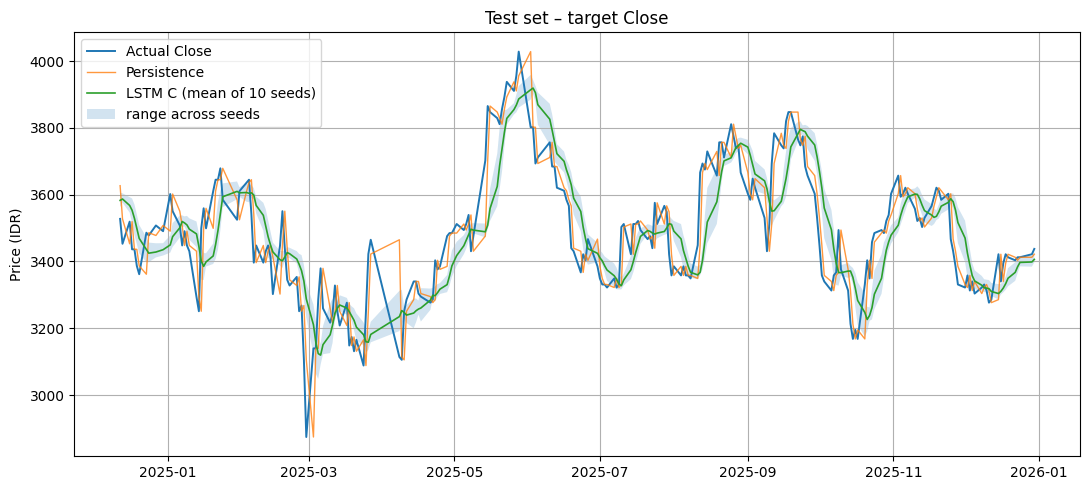

In [ ]:
# ---------- GRAFIK: konfigurasi terpilih vs aktual vs persistence (test) ----------
dates = test.index[WINDOW:]
P = np.vstack([PRED[(selected, s)] for s in SEEDS]).astype(float)
plt.figure(figsize=(11, 5))
plt.plot(dates, ACT["test"], label=f"Actual {TARGET}", lw=1.4)
plt.plot(dates, PERS["test"], label="Persistence", lw=1, alpha=.8)
plt.plot(dates, P.mean(0), label=f"LSTM {selected} (mean of {len(SEEDS)} seeds)", lw=1.2)
plt.fill_between(dates, P.min(0), P.max(0), alpha=.2, label="range across seeds")
plt.title(f"Test set – target {TARGET}"); plt.ylabel("Price (IDR)"); plt.grid(True); plt.legend(loc="upper left")
plt.tight_layout(); plt.savefig(f"grafik_{TARGET}.png", dpi=200); plt.show()

---
# BAGIAN TAMBAHAN: Validasi temporal rolling-origin (expanding window) – komentar Reviewer 2, poin 3

Menjalankan bagian ini **setelah** sel agregasi utama di atas (variabel `df`, `logp`, `train/val/test`, `train_and_predict`, `res` dipakai ulang).
Tiga fold berurutan; train **melebar** (expanding), lalu validation dan test dengan panjang yang sama seperti split utama:

| Fold | Train | Validation | Test |
|---|---|---|---|
| 1 | obs 0 .. N-3B | B hari | B hari |
| 2 | obs 0 .. N-2B | B hari | B hari |
| 3 | obs 0 .. N-B | B hari | B hari = **split utama** (tidak dilatih ulang) |

dengan B = panjang validation split utama. Scaler di-fit ulang hanya pada train tiap fold; seleksi per fold memakai validation fold itu.
Default 5 seed x 15 kombinasi x 2 fold = 150 pelatihan per target (kira-kira 1 jam di Colab).

In [ ]:
# ---------- KONFIGURASI ROLLING-ORIGIN ----------
ROLL_SEEDS   = list(range(5))     # jumlah seed untuk fold 1-2 (fold 3 memakai seed yang sama dari hasil utama)
FOLDS_ALL    = [1, 2, 3]
FOLDS_TO_RUN = [1, 2]             # fold 3 = split utama, TIDAK dilatih ulang
BLOCK = len(val)                  # panjang validation = panjang test pada split utama
assert len(test) == BLOCK, "val dan test split utama harus sama panjang"
N, K = len(df), max(FOLDS_ALL)

def prepare_fold(k):
    test_end   = N - (K - k) * BLOCK
    test_start = test_end - BLOCK
    val_start  = test_start - BLOCK
    tr_, va_, te_ = logp.iloc[:val_start], logp.iloc[val_start:test_start], logp.iloc[test_start:test_end]
    sc = MinMaxScaler().fit(tr_)                                   # fit hanya pada train fold ini
    lo, hi = sc.data_min_[t_idx], sc.data_max_[t_idx]
    inv = lambda z: np.exp(np.asarray(z, dtype=float).ravel() * (hi - lo) + lo)
    sq = {n: make_sequences(sc.transform(p)) for n, p in (("train", tr_), ("val", va_), ("test", te_))}
    F = dict(k=k, inv=inv, SEQ=sq,
             ACT={n: inv(sq[n][1]) for n in sq}, PERS={n: inv(sq[n][2]) for n in sq},
             info=dict(fold=k, n_train=len(tr_), n_val=len(va_), n_test=len(te_),
                       test_range=f"{te_.index[0].date()} -> {te_.index[-1].date()}"))
    assert np.allclose(F["ACT"]["test"], df[TARGET].iloc[test_start + WINDOW:test_end].values), "alignment salah"
    F["pers_val"]  = rmse(F["ACT"]["val"],  F["PERS"]["val"])
    F["pers_test"] = rmse(F["ACT"]["test"], F["PERS"]["test"])
    return F

FOLD = {k: prepare_fold(k) for k in FOLDS_ALL}
# fold 3 HARUS identik dengan split utama
assert FOLD[K]["info"]["n_train"] == len(train), "fold 3 tidak sama dengan split utama"
assert abs(FOLD[K]["pers_test"] - PERS_RES["test"]["rmse"]) < 1e-6, "persistence fold 3 beda dengan split utama"
pd.set_option("display.width", 200)
print(pd.DataFrame([dict(**FOLD[k]["info"], pers_val=FOLD[k]["pers_val"], pers_test=FOLD[k]["pers_test"]) for k in FOLDS_ALL]).to_string(index=False))

 fold  n_train  n_val  n_test               test_range  pers_val  pers_test
    1      676    254     254 2022-10-24 -> 2023-11-08   50.8840    50.8719
    2      930    254     254 2023-11-09 -> 2024-12-02   50.8719    74.4754
    3     1184    254     254 2024-12-03 -> 2025-12-30   74.4754    78.1209


In [ ]:
# ---------- LOOP fold x kombinasi x seed (checkpoint; aman jika Colab terputus) ----------
RCKPT = f"ckpt_roll_{TARGET}.pkl"
roll_rows = pickle.load(open(RCKPT, "rb")) if os.path.exists(RCKPT) else []
done_r = {(r["fold"], r["combo"], r["seed"]) for r in roll_rows}
t0 = time.time()
for k in FOLDS_TO_RUN:
    F = FOLD[k]
    for combo, cols in COMBOS.items():
        for seed in ROLL_SEEDS:
            if (k, combo, seed) in done_r: continue
            Xtr, ytr = F["SEQ"]["train"][0][:, :, cols], F["SEQ"]["train"][1]
            Xva, yva = F["SEQ"]["val"][0][:, :, cols],   F["SEQ"]["val"][1]
            Xte      = F["SEQ"]["test"][0][:, :, cols]
            ptr, pva, pte, n_ep = train_and_predict(Xtr, ytr, Xva, yva, Xte, seed)
            ptr, pva, pte = F["inv"](ptr), F["inv"](pva), F["inv"](pte)
            roll_rows.append(dict(target=TARGET, fold=k, combo=combo, seed=seed,
                                  train_rmse=rmse(F["ACT"]["train"], ptr), val_rmse=rmse(F["ACT"]["val"], pva),
                                  test_rmse=rmse(F["ACT"]["test"], pte), test_mae=mae(F["ACT"]["test"], pte),
                                  test_bias=float(np.mean(pte - F["ACT"]["test"])), epochs=n_ep))
        pickle.dump(roll_rows, open(RCKPT, "wb"))
        print(f"fold {k} | {combo:5s} | {(time.time()-t0)/60:.1f} menit")

# gabungkan dengan fold 3 = hasil eksperimen utama (seed yang sama)
main_res = res if "res" in globals() else pd.read_csv(f"hasil_semua_run_{TARGET}.csv")
main3 = main_res[main_res.seed.isin(ROLL_SEEDS)].assign(fold=3)
keep = ["target", "fold", "combo", "seed", "train_rmse", "val_rmse", "test_rmse", "test_mae", "test_bias", "epochs"]
roll_res = pd.concat([pd.DataFrame(roll_rows), main3[keep]], ignore_index=True)
roll_res = roll_res[roll_res.fold.isin(FOLDS_ALL)]
roll_res.to_csv(f"hasil_rolling_{TARGET}.csv", index=False)
print(roll_res.groupby("fold").size())

fold 1 | O     | 1.7 menit
fold 1 | H     | 3.2 menit
fold 1 | L     | 5.1 menit
fold 1 | C     | 6.7 menit
fold 1 | OH    | 8.2 menit
fold 1 | OL    | 9.7 menit
fold 1 | OC    | 10.8 menit
fold 1 | HL    | 11.9 menit
fold 1 | HC    | 13.4 menit
fold 1 | LC    | 15.0 menit
fold 1 | OHL   | 16.7 menit
fold 1 | OHC   | 18.3 menit
fold 1 | OLC   | 20.1 menit
fold 1 | HLC   | 21.9 menit
fold 1 | OHLC  | 23.2 menit
fold 2 | O     | 24.5 menit
fold 2 | H     | 26.0 menit
fold 2 | L     | 27.4 menit
fold 2 | C     | 28.6 menit
fold 2 | OH    | 30.5 menit
fold 2 | OL    | 32.3 menit
fold 2 | OC    | 33.8 menit
fold 2 | HL    | 35.6 menit
fold 2 | HC    | 37.4 menit
fold 2 | LC    | 38.9 menit
fold 2 | OHL   | 40.3 menit
fold 2 | OHC   | 41.7 menit
fold 2 | OLC   | 43.1 menit
fold 2 | HLC   | 44.5 menit
fold 2 | OHLC  | 46.1 menit
fold
1    75
2    75
3    75
dtype: int64


In [ ]:
# ---------- ANALISIS LINTAS FOLD ----------
order = list(COMBOS)
pers_f = {k: FOLD[k]["pers_test"] for k in FOLDS_ALL}
A = roll_res.groupby(["fold", "combo"]).agg(val=("val_rmse", "mean"), test=("test_rmse", "mean"),
                                            test_sd=("test_rmse", lambda x: np.std(x, ddof=1))).reset_index()
A["ratio"] = A.apply(lambda r: r.test / pers_f[int(r.fold)], axis=1)       # RMSE LSTM / RMSE persistence

sel_rows = []
for k in FOLDS_ALL:
    a = A[A.fold == k].set_index("combo").loc[order]
    s = a.val.idxmin()                                                      # seleksi dari validation fold ini
    runs = roll_res[roll_res.fold == k]
    sel_rows.append(dict(fold=k, test_period=FOLD[k]["info"]["test_range"], selected=s,
                         test_rmse=a.loc[s, "test"], sd=a.loc[s, "test_sd"], persistence=pers_f[k],
                         gap_pct=(a.loc[s, "test"] / pers_f[k] - 1) * 100, best_test=a.test.idxmin(),
                         runs_below_persistence=int((runs.test_rmse < pers_f[k]).sum()), n_runs=len(runs)))
sel_r = pd.DataFrame(sel_rows)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print(f"=== Target {TARGET}: konfigurasi terpilih per fold ===\n", sel_r.to_string(index=False))

R = A.pivot(index="combo", columns="fold", values="ratio").loc[order]
V = A.pivot(index="combo", columns="fold", values="val").loc[order]
T_ = A.pivot(index="combo", columns="fold", values="test").loc[order]
rank_test = T_.rank()
summary = pd.DataFrame({"mean_ratio": R.mean(1), "sd_ratio": R.std(1, ddof=1), "mean_rank_test": rank_test.mean(1)})
print("\n=== RMSE LSTM / RMSE persistence (rata-rata seed) ===\n", pd.concat([R, summary], axis=1).to_string())

def kendall_w(rk):
    m, n = rk.shape[1], rk.shape[0]
    Rsum = rk.sum(1); S = ((Rsum - Rsum.mean())**2).sum()
    W = 12 * S / (m**2 * (n**3 - n)); chi2 = m * (n - 1) * W
    return W, 1 - stats.chi2.cdf(chi2, n - 1)
W, pW = kendall_w(rank_test)
print(f"\nKendall's W (ranking test antar {len(FOLDS_ALL)} fold) = {W:.3f}, p = {pW:.4f}")
for a_, b_ in combinations(FOLDS_ALL, 2):
    rho, p = stats.spearmanr(T_[a_], T_[b_]); print(f"  Spearman test fold {a_} vs {b_}: rho = {rho:.2f} (p = {p:.3f})")
print("  Konfigurasi terpilih sama di semua fold?", sel_r.selected.nunique() == 1, "->", list(sel_r.selected))

=== Target Close: konfigurasi terpilih per fold ===
  fold              test_period selected  test_rmse    sd  persistence  gap_pct best_test  runs_below_persistence  n_runs
    1 2022-10-24 -> 2023-11-08      HLC     162.55 36.59        50.87   219.54         C                       0      75
    2 2023-11-09 -> 2024-12-02       HC     139.45 10.46        74.48    87.25        OL                       0      75
    3 2024-12-03 -> 2025-12-30     OHLC     118.66 11.49        78.12    51.89      OHLC                       0      75

=== RMSE LSTM / RMSE persistence (rata-rata seed) ===
          1    2    3  mean_ratio  sd_ratio  mean_rank_test
combo                                                     
O     2.50 1.98 1.73        2.07      0.39           11.00
H     2.32 2.05 1.56        1.98      0.38            7.00
L     2.08 1.87 1.70        1.88      0.19            6.33
C     2.07 1.89 1.60        1.85      0.24            4.67
OH    3.99 1.92 1.59        2.50      1.30           

\begin{tabular}{lccccc}
\hline
Input & Fold 1 & Fold 2 & Fold 3 & Mean ratio & Mean rank \\
\hline
O & 2.50 & 1.98 & 1.73 & 2.07 & 11.0 \\
H & 2.32 & 2.05 & 1.56 & 1.98 & 7.0 \\
L & 2.08 & 1.87 & 1.70 & 1.88 & 6.3 \\
C & 2.07 & 1.89 & 1.60 & 1.85 & 4.7 \\
OH & 3.99 & 1.92 & 1.59 & 2.50 & 10.0 \\
OL & 3.70 & 1.82 & 1.66 & 2.39 & 8.0 \\
OC & 3.82 & 1.91 & 1.60 & 2.44 & 9.3 \\
HL & 3.87 & 1.89 & 1.62 & 2.46 & 9.3 \\
HC & 3.66 & 1.87 & 1.55 & 2.36 & 5.3 \\
LC & 2.70 & 1.84 & 1.60 & 2.05 & 4.3 \\
OHL & 3.23 & 1.98 & 1.63 & 2.28 & 10.3 \\
OHC & 3.31 & 1.96 & 1.58 & 2.28 & 8.3 \\
OLC & 3.08 & 1.91 & 1.66 & 2.22 & 9.0 \\
HLC & 3.20 & 1.91 & 1.64 & 2.25 & 9.0 \\
OHLC & 3.76 & 1.93 & 1.52 & 2.40 & 8.0 \\
\hline
\end{tabular}

% baris ringkas per fold (untuk tabel tab:rolling):
Close & 1 (2022-10-24 -> 2023-11-08) & HLC & 162.55 & 50.87 & +219.5\% \\
Close & 2 (2023-11-09 -> 2024-12-02) & HC & 139.45 & 74.48 & +87.2\% \\
Close & 3 (2024-12-03 -> 2025-12-30) & OHLC & 118.66 & 78.12 & +51.9\% \\


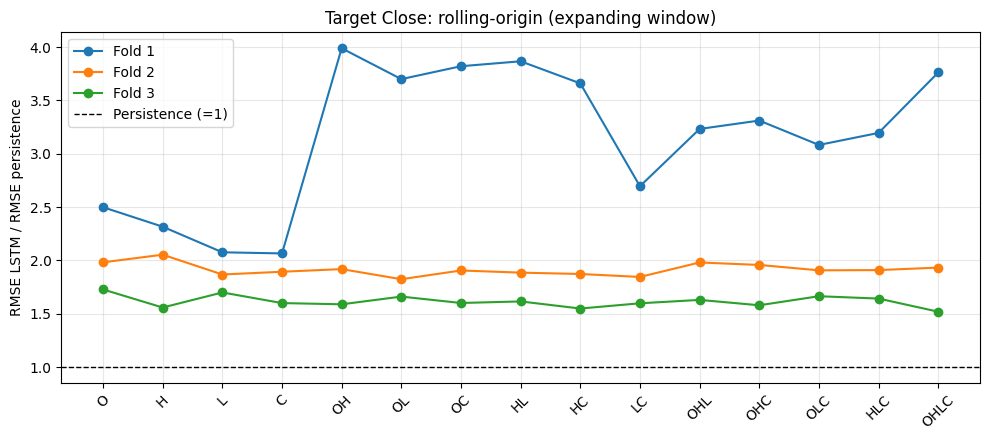

In [ ]:
# ---------- TABEL LaTeX + GRAFIK ROLLING ----------
hdr = " & ".join(f"Fold {k}" for k in FOLDS_ALL)
L = [r"\begin{tabular}{l" + "c" * (len(FOLDS_ALL) + 2) + "}", r"\hline", f"Input & {hdr} & Mean ratio & Mean rank \\\\", r"\hline"]
for c in order:
    L.append(f"{c} & " + " & ".join(f"{R.loc[c, k]:.2f}" for k in FOLDS_ALL) +
             f" & {summary.loc[c,'mean_ratio']:.2f} & {summary.loc[c,'mean_rank_test']:.1f} \\\\")
L += [r"\hline", r"\end{tabular}"]
tex_r = "\n".join(L); print(tex_r)
tex_sel_r = "\n".join(f"{TARGET} & {int(r.fold)} ({r.test_period}) & {r.selected} & {r.test_rmse:.2f} & {r.persistence:.2f} & {r.gap_pct:+.1f}\\% \\\\"
                      for r in sel_r.itertuples())
print("\n% baris ringkas per fold (untuk tabel tab:rolling):\n" + tex_sel_r)
open(f"tabel_rolling_{TARGET}.tex", "w").write(tex_r + "\n\n% ringkas\n" + tex_sel_r + "\n")

fig, ax = plt.subplots(figsize=(10, 4.5))
for k in FOLDS_ALL: ax.plot(order, R[k].values, marker="o", label=f"Fold {k}")
ax.axhline(1, color="k", ls="--", lw=1, label="Persistence (=1)")
ax.set_ylabel("RMSE LSTM / RMSE persistence"); ax.set_title(f"Target {TARGET}: rolling-origin (expanding window)")
ax.grid(True, alpha=.3); ax.legend(); plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(f"grafik_rolling_{TARGET}.png", dpi=200); plt.show()